<a href="https://colab.research.google.com/github/juanchos37/control-microbiologico-python/blob/main/segundo_dia_panificacion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar estilo visual
sns.set_theme(style="whitegrid")

# 1. SIMULACIÓN DE DATOS (Fábrica Bimbo)
# El peso objetivo del Pan Tajado Familiar es 600 gramos
# Generamos 100 mediciones con una variación normal (desviación de 5g)
np.random.seed(42)
pesos = np.random.normal(loc=601.5, scale=4.8, size=100)
lotes = [f"Lote_{i//20 + 1}" for i in range(100)] # 5 lotes diferentes

# Crear el DataFrame de Pandas
df_pan = pd.DataFrame({
    'Lote': lotes,
    'Peso_Gramos': pesos
})

# 2. ANÁLISIS ESTADÍSTICO CON PANDAS
print("--- RESUMEN ESTADÍSTICO DE CALIDAD ---")
# Calculamos la media, el mínimo, el máximo y la desviación estándar
resumen = df_pan['Peso_Gramos'].describe()
print(resumen)

# Identificar cuántos panes están por debajo del límite legal (Supongamos 590g)
limite_inferior = 590
panes_defectuosos = df_pan[df_pan['Peso_Gramos'] < limite_inferior]
print(f"\nAlerta: Se encontraron {len(panes_defectuosos)} panes por debajo del límite legal (590g).")


--- RESUMEN ESTADÍSTICO DE CALIDAD ---
count    100.000000
mean     601.001537
std        4.359208
min      588.925224
25%      598.615653
50%      600.890610
75%      603.448570
max      610.390935
Name: Peso_Gramos, dtype: float64

Alerta: Se encontraron 1 panes por debajo del límite legal (590g).


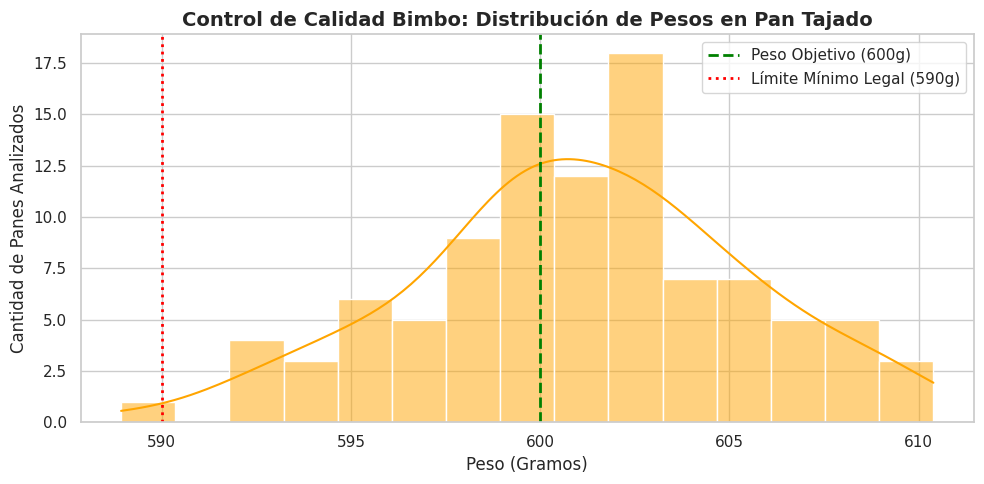

In [2]:
# 3. VISUALIZACIÓN CON SEABORN Y MATPLOTLIB
plt.figure(figsize=(10, 5))

# Creamos un histograma con la curva de distribución
sns.histplot(data=df_pan, x='Peso_Gramos', kde=True, color='orange', bins=15)

# Dibujar líneas de referencia (Límites de calidad)
plt.axvline(x=600, color='green', linestyle='--', linewidth=2, label='Peso Objetivo (600g)')
plt.axvline(x=590, color='red', linestyle=':', linewidth=2, label='Límite Mínimo Legal (590g)')

# Títulos y etiquetas
plt.title('Control de Calidad Bimbo: Distribución de Pesos en Pan Tajado', fontsize=14, fontweight='bold')
plt.xlabel('Peso (Gramos)')
plt.ylabel('Cantidad de Panes Analizados')
plt.legend()

# Mostrar gráfico
plt.tight_layout()
plt.show()


--- REPORTE DE NO CONFORMIDAD EN HORNEADO ---
Minutos con temperatura excesiva (Pan Quemado): 0
Minutos con temperatura deficiente (Pan Crudo): 15

⚠️ Detalle de la caída de temperatura crítica:
 Minuto  Temperatura_C
     66     195.327062
     67     191.557853
     68     194.937691
     69     195.108120
     70     200.328261
     71     200.460643
     72     203.565398
     73     196.953740
     74     197.165556
     75     197.631433
     76     201.903269
     77     199.711775
     78     198.073656
     79     195.868813
     80     202.953543


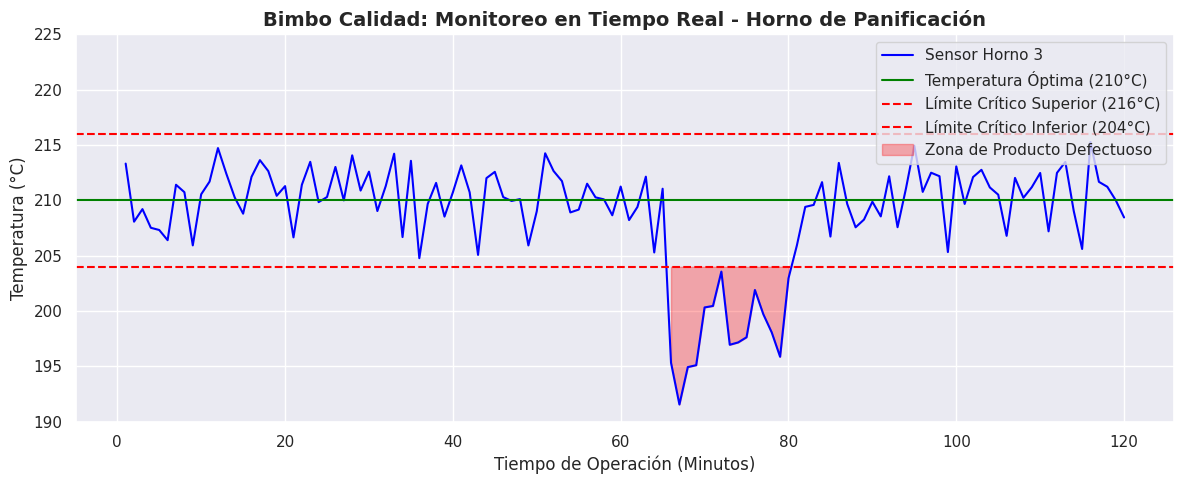

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar estilo visual
sns.set_theme(style="darkgrid")

# 1. SIMULACIÓN DE DATOS (Sensor del Horno Bimbo)
# El horno debe mantener una temperatura óptima de 210°C
# Registramos la temperatura cada minuto durante 2 horas (120 minutos)
np.random.seed(24)
minutos = np.arange(1, 121)
# Simulamos variaciones normales con un salto abrupto por falla de gas en el minuto 70
temperaturas = np.random.normal(loc=210, scale=2.5, size=120)
temperaturas[65:80] = temperaturas[65:80] - 12  # Caída de temperatura simulada

# Crear el DataFrame
df_horno = pd.DataFrame({
    'Minuto': minutos,
    'Temperatura_C': temperaturas
})

# 2. ALGORITMO DE CONTROL DE CALIDAD (Filtros de Alerta)
LIMITE_SUPERIOR = 216
LIMITE_INFERIOR = 204

alertas_alta = df_horno[df_horno['Temperatura_C'] > LIMITE_SUPERIOR]
alertas_baja = df_horno[df_horno['Temperatura_C'] < LIMITE_INFERIOR]

print("--- REPORTE DE NO CONFORMIDAD EN HORNEADO ---")
print(f"Minutos con temperatura excesiva (Pan Quemado): {len(alertas_alta)}")
print(f"Minutos con temperatura deficiente (Pan Crudo): {len(alertas_baja)}")

if not alertas_baja.empty:
    print("\n⚠️ Detalle de la caída de temperatura crítica:")
    print(alertas_baja.to_string(index=False))

# 3. GRÁFICO DE LÍNEA TEMPORAL DE CONTROL
plt.figure(figsize=(12, 5))

# Graficar la línea de temperatura del sensor
sns.lineplot(data=df_horno, x='Minuto', y='Temperatura_C', color='blue', label='Sensor Horno 3')

# Dibujar las franjas de tolerancia del proceso
plt.axhline(y=210, color='green', linestyle='-', label='Temperatura Óptima (210°C)')
plt.axhline(y=LIMITE_SUPERIOR, color='red', linestyle='--', label='Límite Crítico Superior (216°C)')
plt.axhline(y=LIMITE_INFERIOR, color='red', linestyle='--', label='Límite Crítico Inferior (204°C)')

# Resaltar la zona de falla en rojo (Minutos donde el pan salió defectuoso)
plt.fill_between(df_horno['Minuto'], df_horno['Temperatura_C'], LIMITE_INFERIOR,
                 where=(df_horno['Temperatura_C'] < LIMITE_INFERIOR),
                 color='red', alpha=0.3, label='Zona de Producto Defectuoso')

# Títulos profesionales para presentación de indicadores
plt.title('Bimbo Calidad: Monitoreo en Tiempo Real - Horno de Panificación', fontsize=14, fontweight='bold')
plt.xlabel('Tiempo de Operación (Minutos)')
plt.ylabel('Temperatura (°C)')
plt.legend(loc='upper right')
plt.ylim(190, 225)

plt.tight_layout()
plt.show()


In [7]:
import pandas as pd
import openpyxl
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter

# 1. SIMULACIÓN DE DATOS CON PANDAS (Mermas por Turno en Bimbo)
# Simulamos el registro de pérdidas en kilogramos para 3 turnos (Mañana, Tarde, Noche)
data_mermas = {
    'Fecha': ['2026-10-30', '2026-10-30', '2026-10-30', '2026-10-31', '2026-10-31', '2026-10-31'],
    'Turno': ['Mañana', 'Tarde', 'Noche', 'Mañana', 'Tarde', 'Noche'],
    'Masa_Desperdiciada_Kg': [12.5, 24.8, 35.2, 14.1, 19.5, 42.0],  # Alerta en la noche
    'Pan_Deforme_Unidades': [45, 80, 110, 50, 75, 130]
}

df_mermas = pd.DataFrame(data_mermas)

# 2. EXPORTAR A EXCEL USANDO OPENPYXL
nombre_archivo = "Reporte_Mermas_Bimbo.xlsx"
df_mermas.to_excel(nombre_archivo, index=False, sheet_name="Control Mermas")

# 3. DISEÑO Y FORMATO AUTOMATIZADO DEL EXCEL
wb = openpyxl.load_workbook(nombre_archivo)
ws = wb["Control Mermas"]

# Definir estilos visuales profesionales
fuente_titulo = Font(name="Arial", size=11, bold=True, color="FFFFFF")
relleno_azul_bimbo = PatternFill(start_color="1F497D", end_color="1F497D", fill_type="solid") # Azul corporativo
relleno_alerta_roja = PatternFill(start_color="FCE4D6", end_color="FCE4D6", fill_type="solid") # Rojo/Naranja suave para fallas
fuente_alerta = Font(name="Arial", size=11, color="C00000", bold=True)
alineacion_centro = Alignment(horizontal="center", vertical="center")

# Definir bordes delgados
borde_delgado = Border(
    left=Side(style='thin', color='D9D9D9'),
    right=Side(style='thin', color='D9D9D9'),
    top=Side(style='thin', color='D9D9D9'),
    bottom=Side(style='thin', color='D9D9D9')
)

# Aplicar formato a las cabeceras (Fila 1)
for cell in ws[1]:
    cell.font = fuente_titulo
    cell.fill = relleno_azul_bimbo
    cell.alignment = alineacion_centro
ws.row_dimensions[1].height = 25

# Aplicar formato a los datos y añadir lógica de control de calidad
limite_merma_masa = 30.0 # Más de 30kg de masa perdida es crítico

for row in range(2, ws.max_row + 1):
    ws.row_dimensions[row].height = 20
    # Leer el valor de la columna 3 (Masa Desperdiciada)
    valor_merma = ws.cell(row=row, column=3).value

    # Evaluar los límites de calidad celda por celda
    for col in range(1, ws.max_column + 1):
        cell = ws.cell(row=row, column=col)
        cell.border = borde_delgado
        if col in [1, 2]: # Centrar fechas y turnos
            cell.alignment = alineacion_centro

        # Si la merma supera el límite, pintamos toda la fila de alerta
        if valor_merma > limite_merma_masa:
            cell.fill = relleno_alerta_roja
            if col == 3:
                cell.font = fuente_alerta

# Autoajustar el ancho de las columnas según el texto
for col in ws.columns:
    max_len = max(len(str(cell.value or '')) for cell in col)
    col_letter = get_column_letter(col[0].column)
    ws.column_dimensions[col_letter].width = max(max_len + 3, 12)

# Guardar los cambios finales
wb.save(nombre_archivo)
print(f"¡Éxito! El archivo '{nombre_archivo}' ha sido generado y formateado automáticamente.")


¡Éxito! El archivo 'Reporte_Mermas_Bimbo.xlsx' ha sido generado y formateado automáticamente.


--- PROMEDIO DE UNIDADES DEVUELTAS POR DÍA Y TURNO ---
Día_Semana Turno_Empaque  Unidades_Devueltas
   Viernes         Noche          149.750000
     Lunes         Noche           65.333333
    Sábado        Mañana           59.142857
    Martes        Mañana           58.750000
   Domingo        Mañana           52.285714


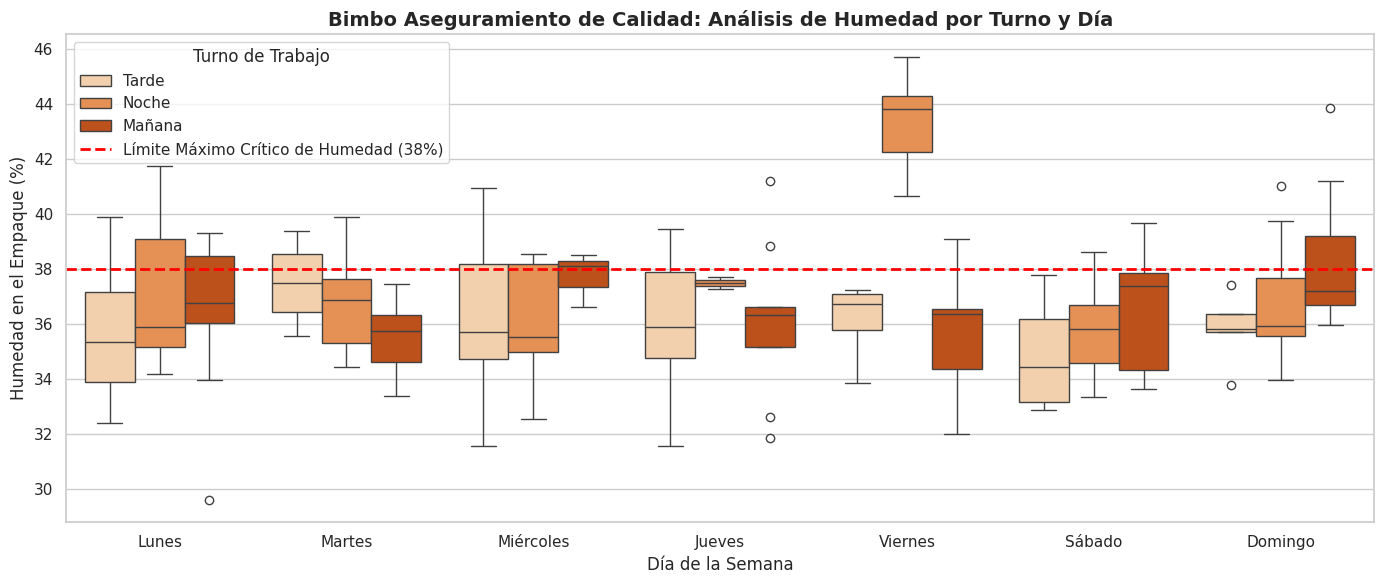

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar estilo visual
sns.set_theme(style="whitegrid")

# 1. SIMULACIÓN DE DATOS (Devoluciones por mohos en agencias Bimbo)
# Simulamos un historial de 150 registros de lotes devueltos por presencia de hongos
np.random.seed(56)

dias = ['Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes', 'Sábado', 'Domingo']
turnos = ['Mañana', 'Tarde', 'Noche']

# Generamos datos aleatorios estructurados
data_devoluciones = pd.DataFrame({
    'Día_Semana': np.random.choice(dias, size=150),
    'Turno_Empaque': np.random.choice(turnos, size=150),
    'Humedad_Empaque_Porcentaje': np.random.normal(loc=36.5, scale=2.1, size=150),
    'Unidades_Devueltas': np.random.randint(10, 80, size=150)
})

# Simulamos una falla real en la planta:
# Los días Viernes en el turno de la Noche hubo una falla en los ventiladores de enfriamiento,
# elevando la humedad y disparando las devoluciones drásticamente.
condicion_falla = (data_devoluciones['Día_Semana'] == 'Viernes') & (data_devoluciones['Turno_Empaque'] == 'Noche')
data_devoluciones.loc[condicion_falla, 'Humedad_Empaque_Porcentaje'] += 6.5
data_devoluciones.loc[condicion_falla, 'Unidades_Devueltas'] += 120

# 2. ANÁLISIS DE DATOS CON PANDAS (Agrupamiento por variables)
print("--- PROMEDIO DE UNIDADES DEVUELTAS POR DÍA Y TURNO ---")
reporte_critico = data_devoluciones.groupby(['Día_Semana', 'Turno_Empaque'])['Unidades_Devueltas'].mean().reset_index()
# Ordenamos de mayor a menor para ver los peores casos
print(reporte_critico.sort_values(by='Unidades_Devueltas', ascending=False).head(5).to_string(index=False))


# 3. VISUALIZACIÓN AVANZADA DE CALIDAD (Seaborn FacetGrid / Catplot)
# Vamos a ver la relación entre la Humedad del empaque y el Turno para cada Día
plt.figure(figsize=(14, 6))

# Usamos un Boxplot (Diagrama de cajas) para ver la dispersión de la humedad
sns.boxplot(
    data=data_devoluciones,
    x='Día_Semana',
    y='Humedad_Empaque_Porcentaje',
    hue='Turno_Empaque',
    palette='Oranges',
    order=dias
)

# Línea de referencia de calidad: El pan no debe superar el 38% de humedad al empacarse
plt.axhline(y=38, color='red', linestyle='--', linewidth=2, label='Límite Máximo Crítico de Humedad (38%)')

# Personalización del gráfico
plt.title('Bimbo Aseguramiento de Calidad: Análisis de Humedad por Turno y Día', fontsize=14, fontweight='bold')
plt.xlabel('Día de la Semana')
plt.ylabel('Humedad en el Empaque (%)')
plt.legend(title='Turno de Trabajo', loc='upper left')

plt.tight_layout()
plt.show()


In [10]:
import sqlite3
import pandas as pd

# 1. CREAR LA BASE DE DATOS INDUSTRIAL EN MEMORIA
# Simulamos la base de datos de Recepción de Materias Primas de Bimbo
conexion = sqlite3.connect(':memory:')
cursor = conexion.cursor()

# Crear tabla de Control de Proveedores de Harina
cursor.execute('''
    CREATE TABLE Recepcion_Harina (
        ID_Lote INTEGER PRIMARY KEY AUTOINCREMENT,
        Proveedor TEXT,
        Humedad_Porcentaje REAL,
        Proteina_Porcentaje REAL,
        Cenizas_Porcentaje REAL,
        Estado_Aprobacion TEXT
    )
''')

# Insertar datos históricos de inspecciones en laboratorio
datos_inspeccion = [
    ('Proveedor_Alfa', 13.2, 11.5, 0.52, 'Aprobado'),
    ('Proveedor_Beta', 14.8, 10.2, 0.65, 'Rechazado'), # Humedad muy alta (máx 14.5%)
    ('Proveedor_Alfa', 12.8, 12.0, 0.50, 'Aprobado'),
    ('Proveedor_Gamma', 13.0, 9.5, 0.48, 'Rechazado'),  # Proteína muy baja (mín 10%)
    ('Proveedor_Beta', 13.5, 11.2, 0.53, 'Aprobado'),
    ('Proveedor_Gamma', 15.1, 10.8, 0.58, 'Rechazado')  # Humedad excesiva
]

cursor.executemany('''
    INSERT INTO Recepcion_Harina (Proveedor, Humedad_Porcentaje, Proteina_Porcentaje, Cenizas_Porcentaje, Estado_Aprobacion)
    VALUES (?, ?, ?, ?, ?)
''', datos_inspeccion)
conexion.commit()


# 2. CONSULTA SQL DE AUDITORÍA (Tu Rol como Tecnólogo)
# Queremos traer solo los lotes RECHAZADOS para pasárselos al departamento de compras
consulta_sql = """
    SELECT Proveedor, Humedad_Porcentaje, Proteina_Porcentaje, Estado_Aprobacion
    FROM Recepcion_Harina
    WHERE Estado_Aprobacion = 'Rechazado'
    ORDER BY Humedad_Porcentaje DESC;
"""

# 3. CONECTAR SQL CON PANDAS
# Pandas lee la consulta SQL directamente y la transforma en un DataFrame
df_auditoria = pd.read_sql_query(consulta_sql, conexion)

print("--- ALERTA DE MATERIA PRIMA NO CONFORME (EXTRACTO SQL) ---")
print(df_auditoria.to_string(index=False))


# 4. CONSULTA DE CONTROL: Rendimiento por Proveedor
consulta_rendimiento = """
    SELECT Proveedor,
           COUNT(*) as Total_Lotes,
           SUM(CASE WHEN Estado_Aprobacion = 'Rechazado' THEN 1 ELSE 0 END) as Lotes_Rechazados
    FROM Recepcion_Harina
    GROUP BY Proveedor;
"""
df_proveedores = pd.read_sql_query(consulta_rendimiento, conexion)

print("\n--- INFORME DE DESEMPEÑO DE PROVEEDORES ---")
print(df_proveedores.to_string(index=False))

# Cerrar la conexión
conexion.close()


--- ALERTA DE MATERIA PRIMA NO CONFORME (EXTRACTO SQL) ---
      Proveedor  Humedad_Porcentaje  Proteina_Porcentaje Estado_Aprobacion
Proveedor_Gamma                15.1                 10.8         Rechazado
 Proveedor_Beta                14.8                 10.2         Rechazado
Proveedor_Gamma                13.0                  9.5         Rechazado

--- INFORME DE DESEMPEÑO DE PROVEEDORES ---
      Proveedor  Total_Lotes  Lotes_Rechazados
 Proveedor_Alfa            2                 0
 Proveedor_Beta            2                 1
Proveedor_Gamma            2                 2


In [17]:
import sqlite3
import pandas as pd
import openpyxl
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter

# 1. SIMULACIÓN DE LA BASE DE DATOS (Servidor Central)
conexion = sqlite3.connect(':memory:')
cursor = conexion.cursor()

cursor.execute('''
    CREATE TABLE Recepcion_Harina (
        ID_Lote INTEGER PRIMARY KEY AUTOINCREMENT,
        Proveedor TEXT,
        Humedad_Porcentaje REAL,
        Proteina_Porcentaje REAL,
        Cenizas_Porcentaje REAL,
        Estado_Aprobacion TEXT
    )
''')

datos_inspeccion = [
    ('Proveedor_Alfa', 13.2, 11.5, 0.52, 'Aprobado'),
    ('Proveedor_Beta', 14.8, 10.2, 0.65, 'Rechazado'),
    ('Proveedor_Alfa', 12.8, 12.0, 0.50, 'Aprobado'),
    ('Proveedor_Gamma', 13.0, 9.5, 0.48, 'Rechazado'),
    ('Proveedor_Beta', 13.5, 11.2, 0.53, 'Aprobado'),
    ('Proveedor_Gamma', 15.1, 10.8, 0.58, 'Rechazado')
]

cursor.executemany('''
    INSERT INTO Recepcion_Harina (Proveedor, Humedad_Porcentaje, Proteina_Porcentaje, Cenizas_Porcentaje, Estado_Aprobacion)
    VALUES (?, ?, ?, ?, ?)
''', datos_inspeccion)
conexion.commit()

# 2. EXTRACCIÓN DE DATOS CON SQL Y PANDAS
consulta_sql = "SELECT * FROM Recepcion_Harina;"
df_calidad = pd.read_sql_query(consulta_sql, conexion)
conexion.close()

# 3. EXPORTACIÓN INICIAL A EXCEL
nombre_excel = "Auditoria_Proveedores_Bimbo.xlsx"
df_calidad.to_excel(nombre_excel, index=False, sheet_name="Materia Prima")

# 4. DISEÑO ESTÉTICO DE CALIDAD CON OPENPYXL
wb = openpyxl.load_workbook(nombre_excel)
ws = wb["Materia Prima"]

fuente_cabecera = Font(name="Segoe UI", size=11, bold=True, color="FFFFFF")
relleno_bimbo = PatternFill(start_color="1F497D", end_color="1F497D", fill_type="solid")
relleno_rechazado = PatternFill(start_color="FCE4D6", end_color="FCE4D6", fill_type="solid")
fuente_rechazado = Font(name="Segoe UI", size=11, bold=True, color="C00000")
alineacion_centro = Alignment(horizontal="center", vertical="center")

borde_fino = Border(
    left=Side(style='thin', color='D9D9D9'),
    right=Side(style='thin', color='D9D9D9'),
    top=Side(style='thin', color='D9D9D9'),
    bottom=Side(style='thin', color='D9D9D9')
)

# Dar formato a las cabeceras (Fila 1)
for cell_row in ws.iter_rows(min_row=1, max_row=1):
    for cell in cell_row:
        cell.font = fuente_cabecera
        cell.fill = relleno_bimbo
        cell.alignment = alineacion_centro
ws.row_dimensions[1].height = 26

# Recorrer filas de datos para aplicar formato condicional
for row in range(2, ws.max_row + 1):
    ws.row_dimensions[row].height = 20
    estado = ws.cell(row=row, column=6).value

    for col in range(1, ws.max_column + 1):
        cell = ws.cell(row=row, column=col)
        cell.border = borde_fino

        # LÓGICA REESCRITA (Sin corchetes): Centrar columna 1 (ID) y columna 6 (Estado)
        if col == 1 or col == 6:
            cell.alignment = alineacion_centro

        if estado == 'Rechazado':
            cell.fill = relleno_rechazado
            if col == 6:
                cell.font = fuente_rechazado

# Autoajustar el ancho de las columnas (CORREGIDO)
for col in ws.columns:
    max_len = max(len(str(cell.value or '')) for cell in col)
    col_letter = get_column_letter(col[0].column)
    ws.column_dimensions[col_letter].width = max(max_len + 4, 15)

wb.save(nombre_excel)
print(f"📄 ¡Reporte generado con éxito! Archivo creado sin errores: '{nombre_excel}'")


📄 ¡Reporte generado con éxito! Archivo creado sin errores: 'Auditoria_Proveedores_Bimbo.xlsx'
